# 03 — Análise de vídeo de fisioterapia

O enunciado pede: processar vídeos clínicos, **detectar movimentos fora do padrão esperado** com análise postural
e detecção de objetos, e **gerar relatórios automáticos** indicando desvios.

| Etapa | Ferramenta | Papel |
|---|---|---|
| Análise postural | **MediaPipe Pose** | Localiza 33 pontos do corpo; deles saem os ângulos das articulações |
| Detecção | **YOLOv8** | Localiza a pessoa no quadro; a trajetória alimenta a análise de movimentação |
| Desvios | Regras sobre os ângulos | Compara a execução com o padrão esperado |

> O enunciado cita "modelos como OpenPose" para a postura. Usamos o MediaPipe Pose, que faz o mesmo trabalho
> (estimar os pontos do corpo) e foi a ferramenta vista nas aulas.

**Dados:** [REHAB24-6](https://zenodo.org/records/13305826) (licença CC BY-NC 4.0): vídeos de 10 pessoas fazendo
6 exercícios de reabilitação, com cada repetição rotulada por um fisioterapeuta como correta ou incorreta.
Para baixar: `python scripts/baixar_dados.py rehab`

In [1]:
import os
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import json
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.anomalias.movimentacao import detectar_anomalias_movimentacao
from src.fusao.alerta import montar_relatorio_padrao
from src.fusao.risco import calcular_risco
from src.video.desvios import aprender_faixas, aprender_padrao, avaliar_execucao, detectar_desvios
from src.video.detector import detectar_pessoa
from src.video.pose import ANGULOS, extrair_poses

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)

PASTA = Path("data/raw/rehab24-6")
COLUNAS = ["frame", "tempo_s", *ANGULOS]
PASSO = 3  # analisamos um a cada 3 quadros (10 por segundo)

## 1. O exercício escolhido

**Exercício 1: abdução do braço** (elevar lateralmente o braço direito estendido), filmado de frente.
A articulação principal é o **ombro direito**.

In [2]:
segmentacao = pd.read_csv(PASTA / "Segmentation.csv", sep=";")
repeticoes = segmentacao[(segmentacao.exercise_id == 1) & (segmentacao.cam17_orientation == "front")]
print("Repetições frontais do exercício 1:", len(repeticoes))
repeticoes.groupby("person_id")["correctness"].agg(corretas="sum", incorretas=lambda s: (s == 0).sum())

Repetições frontais do exercício 1: 88


,corretas,incorretas
person_id,,
1,10,5
2,5,5
3,5,5
4,6,5
5,5,6
7,5,5
8,5,5
9,6,5


## 2. Análise postural com MediaPipe

Para cada quadro, o MediaPipe devolve 33 pontos do corpo. Com três pontos calculamos um ângulo:
por exemplo, quadril, ombro e cotovelo dão o **ângulo do ombro** (0° = braço junto ao corpo, 90° = braço na horizontal).

In [3]:
def caminho_video(video_id: str) -> Path:
    return PASTA / "videos" / "Ex1" / f"{video_id}-Camera17-30fps.mp4"


def quadro_do_video(caminho, frame, recorte=None):
    captura = cv2.VideoCapture(str(caminho))
    captura.set(cv2.CAP_PROP_POS_FRAMES, frame)
    _, quadro = captura.read()
    captura.release()
    quadro = cv2.cvtColor(quadro, cv2.COLOR_BGR2RGB)
    return quadro[:, recorte[0] : recorte[1]] if recorte else quadro


def repeticao(video_id: str, numero: int) -> pd.Series:
    return segmentacao[(segmentacao.video_id == video_id) & (segmentacao.repetition_number == numero)].iloc[0]


correta, incorreta = repeticao("PM_122", 3), repeticao("PM_122", 9)
anotado = Path("results/exemplo_pose_anotado.mp4")
angulos_correta = extrair_poses(caminho_video("PM_122"), saida_anotada=anotado,
                                intervalo=(correta.first_frame, correta.last_frame + 1), passo=PASSO)
angulos_incorreta = extrair_poses(caminho_video("PM_122"), intervalo=(incorreta.first_frame, incorreta.last_frame + 1), passo=PASSO)
angulos_correta.round(1).head()

,frame,tempo_s,cotovelo_esq,cotovelo_dir,ombro_esq,ombro_dir,quadril_esq,quadril_dir,joelho_esq,joelho_dir
0,391,0.0,179.6,176.4,17.5,17.2,168.0,169.5,175.2,176.7
1,394,0.1,178.5,176.7,18.1,17.3,168.3,169.8,176.2,176.8
2,397,0.2,179.3,177.8,17.8,17.8,168.4,170.4,176.8,176.7
3,400,0.3,178.9,175.6,16.2,18.8,169.4,169.9,177.7,177.2
4,403,0.4,176.9,172.7,17.3,24.3,169.2,169.9,177.7,177.0


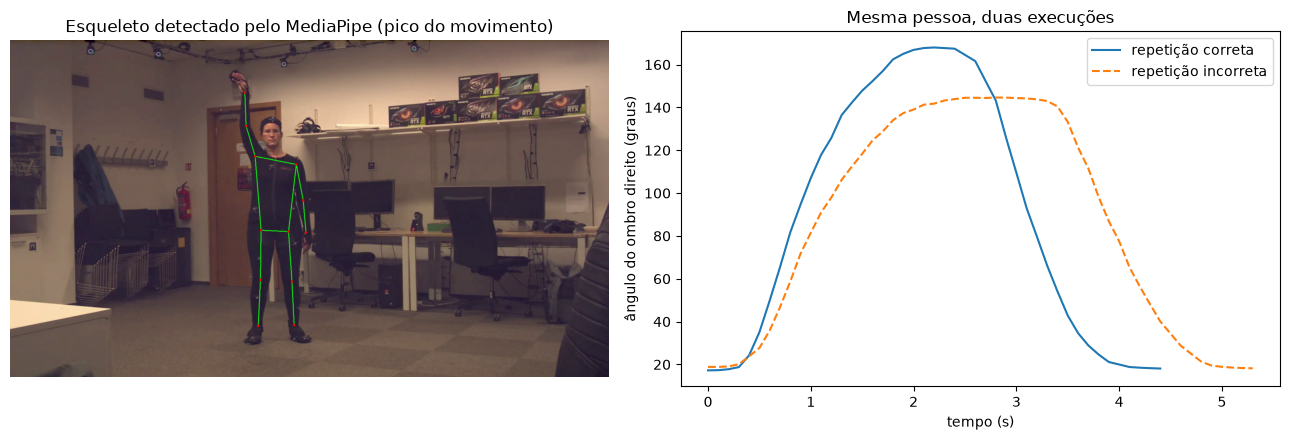

In [4]:
pico = int(angulos_correta["ombro_dir"].idxmax())
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
eixos[0].imshow(quadro_do_video(anotado, pico))
eixos[0].set_title("Esqueleto detectado pelo MediaPipe (pico do movimento)")
eixos[0].axis("off")
eixos[1].plot(angulos_correta["tempo_s"], angulos_correta["ombro_dir"], label="repetição correta")
eixos[1].plot(angulos_incorreta["tempo_s"], angulos_incorreta["ombro_dir"], label="repetição incorreta", linestyle="--")
eixos[1].set(xlabel="tempo (s)", ylabel="ângulo do ombro direito (graus)", title="Mesma pessoa, duas execuções")
eixos[1].legend()
plt.tight_layout()
plt.show()

Na repetição incorreta desta pessoa o braço sobe menos. O que o fisioterapeuta marcou como erro foi
a **amplitude insuficiente com compensação do tronco**:

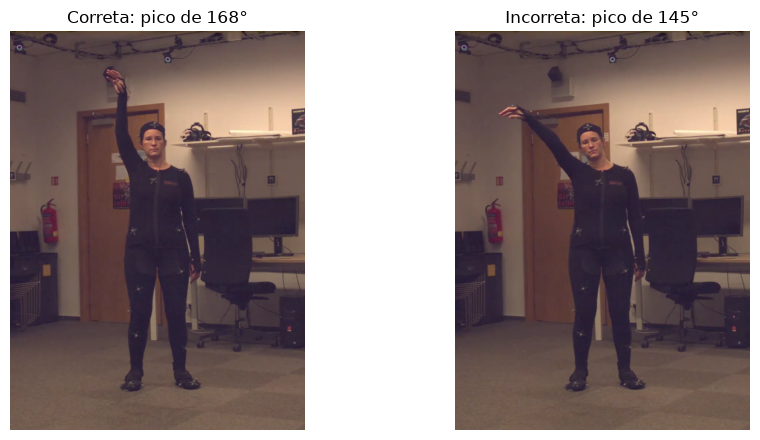

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.5))
for eixo, (titulo, rep, tabela) in zip(eixos, [("Correta", correta, angulos_correta), ("Incorreta", incorreta, angulos_incorreta)]):
    frame_pico = int(tabela.loc[tabela["ombro_dir"].idxmax(), "frame"])
    eixo.imshow(quadro_do_video(caminho_video("PM_122"), frame_pico, recorte=(450, 1250)))
    eixo.set_title(f"{titulo}: pico de {tabela['ombro_dir'].max():.0f}°")
    eixo.axis("off")
plt.tight_layout()
plt.show()

## 3. Ângulos de todas as repetições

Extraímos os ângulos das 88 repetições frontais. Como leva cerca de 15 minutos, o resultado fica guardado em um CSV
e é reaproveitado nas execuções seguintes.

In [6]:
CACHE = PASTA / "angulos_ex1_frontal.csv"
if CACHE.exists():
    todos = pd.read_csv(CACHE)
else:
    partes = []
    for r in repeticoes.itertuples():
        tabela = extrair_poses(caminho_video(r.video_id), intervalo=(r.first_frame, r.last_frame + 1), passo=PASSO)
        tabela.insert(0, "correta", r.correctness)
        tabela.insert(0, "pessoa", r.person_id)
        tabela.insert(0, "repeticao", r.repetition_number)
        tabela.insert(0, "video_id", r.video_id)
        partes.append(tabela)
    todos = pd.concat(partes)
    todos.to_csv(CACHE, index=False)

execucoes = [
    {"pessoa": int(g["pessoa"].iloc[0]), "correta": int(g["correta"].iloc[0]), "angulos": g[COLUNAS].reset_index(drop=True)}
    for _, g in todos.groupby(["video_id", "repeticao"])
]
print(len(execucoes), "repetições |", len(todos), "quadros analisados")
print("Quadros sem pessoa detectada:", f"{todos['ombro_dir'].isna().mean():.1%}")

88 repetições | 4692 quadros analisados
Quadros sem pessoa detectada: 0.1%


## 4. Primeira tentativa: um padrão único para todos (não funcionou)

A ideia inicial era aprender a **faixa esperada de cada ângulo** com as repetições corretas de algumas pessoas
e aplicar em pessoas diferentes.

In [7]:
pessoas = sorted({e["pessoa"] for e in execucoes})
pessoas_referencia = pessoas[:5]
faixas_gerais = aprender_faixas([e["angulos"] for e in execucoes if e["pessoa"] in pessoas_referencia and e["correta"]], margem=10)

resultado = {0: [0, 0], 1: [0, 0]}
for e in execucoes:
    if e["pessoa"] in pessoas_referencia:
        continue
    resultado[e["correta"]][1] += 1
    resultado[e["correta"]][0] += bool(detectar_desvios(e["angulos"], faixas_gerais, min_duracao_s=0.3))

print("Faixa geral aprendida para o ombro direito:", tuple(round(v) for v in faixas_gerais["ombro_dir"]))
print(f"Repetições incorretas detectadas: {resultado[0][0]} de {resultado[0][1]}")
print(f"Repetições corretas com falso alarme: {resultado[1][0]} de {resultado[1][1]}")

Faixa geral aprendida para o ombro direito: (2, 179)
Repetições incorretas detectadas: 0 de 15
Repetições corretas com falso alarme: 0 de 16


In [8]:
picos = pd.DataFrame([{"pessoa": e["pessoa"], "execução": "correta" if e["correta"] else "incorreta",
                       "pico do ombro direito": e["angulos"]["ombro_dir"].max()} for e in execucoes])
picos.pivot_table(index="pessoa", columns="execução", values="pico do ombro direito", aggfunc="median").round(0)

execução,correta,incorreta
pessoa,,
1,140.0,124.0
2,119.0,144.0
3,133.0,151.0
4,106.0,147.0
5,142.0,131.0
7,168.0,145.0
8,126.0,132.0
9,134.0,98.0


**Por que falhou:** cada pessoa executa o exercício "corretamente" com uma amplitude diferente (a tabela acima
mostra picos corretos de cerca de 110° a 170°), e o fisioterapeuta pediu **erros diferentes para cada pessoa**.
Uma faixa única que aceite todas as execuções corretas fica larga demais (0° a 180° no ombro) e aceita qualquer coisa.

## 5. Abordagem adotada: padrão individual do paciente

O padrão passa a ser **do próprio paciente**: aprendido de repetições que ele fez corretamente sob supervisão do
fisioterapeuta. Depois, cada nova execução é comparada com esse padrão por dois critérios:

1. **Faixa de cada ângulo:** algum ângulo ficou fora da faixa habitual do paciente por mais de 0,3 s?
2. **Amplitude:** o pico do movimento (ângulo máximo do ombro) ficou abaixo ou acima do habitual?

**Avaliação:** para cada pessoa, as **2 primeiras repetições corretas** formam o padrão. As demais repetições
(corretas e incorretas) são o teste.

In [9]:
N_REFERENCIA = 2
linhas = []
for pessoa in pessoas:
    corretas = [e for e in execucoes if e["pessoa"] == pessoa and e["correta"]]
    incorretas = [e for e in execucoes if e["pessoa"] == pessoa and not e["correta"]]
    padrao = aprender_padrao([e["angulos"] for e in corretas[:N_REFERENCIA]], "ombro_dir", margem=10, tolerancia=15)
    restantes = corretas[N_REFERENCIA:]
    linhas.append({
        "pessoa": pessoa,
        "amplitude esperada": f"{padrao['amplitude'][0]:.0f}° a {padrao['amplitude'][1]:.0f}°",
        "incorretas": len(incorretas),
        "incorretas detectadas": sum(bool(avaliar_execucao(e["angulos"], padrao)) for e in incorretas),
        "corretas de teste": len(restantes),
        "falsos alarmes": sum(bool(avaliar_execucao(e["angulos"], padrao)) for e in restantes),
    })
por_pessoa = pd.DataFrame(linhas)
por_pessoa

,pessoa,amplitude esperada,incorretas,incorretas detectadas,corretas de teste,falsos alarmes
0,1,125° a 187°,5,3,8,0
1,2,101° a 135°,5,5,3,0
2,3,115° a 150°,5,4,3,0
3,4,88° a 120°,5,5,4,2
4,5,127° a 168°,6,2,3,1
5,7,154° a 184°,5,5,3,0
6,8,112° a 143°,5,2,3,0
7,9,115° a 149°,5,5,4,2


In [10]:
detectadas, incorretas = por_pessoa["incorretas detectadas"].sum(), por_pessoa["incorretas"].sum()
alarmes, corretas_teste = por_pessoa["falsos alarmes"].sum(), por_pessoa["corretas de teste"].sum()
print(f"Repetições incorretas detectadas: {detectadas} de {incorretas} ({detectadas / incorretas:.0%})")
print(f"Falsos alarmes em repetições corretas: {alarmes} de {corretas_teste} ({alarmes / corretas_teste:.0%})")

Repetições incorretas detectadas: 31 de 41 (76%)
Falsos alarmes em repetições corretas: 5 de 31 (16%)


Com o padrão individual, a maior parte das execuções incorretas é detectada, com poucos falsos alarmes.

**Limitações:**
- Erros que não mudam os ângulos vistos de frente (por exemplo, levar o braço para a frente em vez de para o lado) passam despercebidos.
- Com só 2 repetições de referência, uma execução correta um pouco diferente das de referência gera falso alarme.
- A margem (10°) e a tolerância de amplitude (15°) foram escolhidas olhando estes mesmos dados.

## 6. Detecção da pessoa com YOLOv8

O YOLOv8 pré-treinado localiza pessoas no quadro. Guardamos o centro e o tamanho da caixa do paciente
(a maior caixa, quando há mais de uma pessoa) e quantas pessoas aparecem.

In [11]:
trajetoria = detectar_pessoa(caminho_video("PM_122"), intervalo=(correta.first_frame, correta.last_frame + 1), passo=PASSO)
trajetoria.round(3).head()

,frame,tempo_s,x_centro,y_centro,largura,altura,n_pessoas
0,391,0.0,0.439,0.568,0.133,0.679,2
1,394,0.1,0.439,0.568,0.134,0.679,2
2,397,0.2,0.439,0.569,0.134,0.678,2
3,400,0.3,0.436,0.569,0.138,0.677,2
4,403,0.4,0.428,0.569,0.155,0.677,2


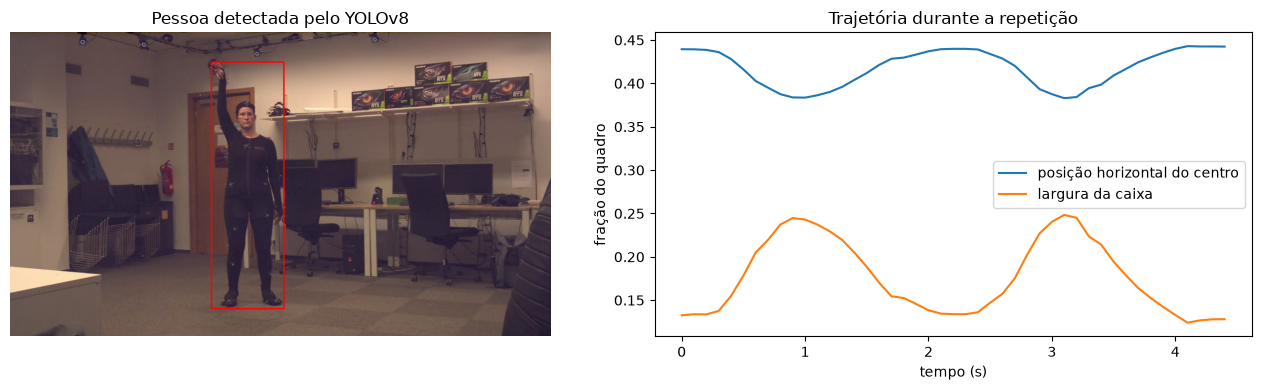

Pessoas no quadro (máximo): 2
Eventos de movimentação: nenhum


In [12]:
quadro = quadro_do_video(caminho_video("PM_122"), int(trajetoria.loc[len(trajetoria) // 2, "frame"]))
altura, largura = quadro.shape[:2]
linha = trajetoria.loc[len(trajetoria) // 2]
x1, y1 = int((linha.x_centro - linha.largura / 2) * largura), int((linha.y_centro - linha.altura / 2) * altura)
x2, y2 = int((linha.x_centro + linha.largura / 2) * largura), int((linha.y_centro + linha.altura / 2) * altura)
cv2.rectangle(quadro, (x1, y1), (x2, y2), (255, 0, 0), 4)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].imshow(quadro)
eixos[0].set_title("Pessoa detectada pelo YOLOv8")
eixos[0].axis("off")
eixos[1].plot(trajetoria["tempo_s"], trajetoria["x_centro"], label="posição horizontal do centro")
eixos[1].plot(trajetoria["tempo_s"], trajetoria["largura"], label="largura da caixa")
eixos[1].set(xlabel="tempo (s)", ylabel="fração do quadro", title="Trajetória durante a repetição")
eixos[1].legend()
plt.tight_layout()
plt.show()

print("Pessoas no quadro (máximo):", int(trajetoria["n_pessoas"].max()))
print("Eventos de movimentação:", detectar_anomalias_movimentacao(trajetoria) or "nenhum")

Em uma repetição de poucos segundos, com o paciente no lugar e dentro do quadro, não há evento de movimentação
(o esperado). As regras de movimentação (imobilidade, saída da área, ausência) estão demonstradas no notebook 04.

## 7. Clipes de demonstração e padrão do paciente

Recortamos quatro repetições da pessoa 7 para a demonstração do fluxo completo (reduzidas para 960x540):
duas corretas de **referência**, uma correta e uma incorreta de **teste**.

> Vídeos do dataset REHAB24-6 (Černek, Sedmidubský, Budíková), licença CC BY-NC 4.0.

In [13]:
def recortar(video_id: str, numero: int, destino: Path) -> Path:
    rep = repeticao(video_id, numero)
    captura = cv2.VideoCapture(str(caminho_video(video_id)))
    captura.set(cv2.CAP_PROP_POS_FRAMES, int(rep.first_frame))
    gravador = cv2.VideoWriter(str(destino), cv2.VideoWriter_fourcc(*"mp4v"), 30, (960, 540))
    for _ in range(int(rep.first_frame), int(rep.last_frame) + 1):
        lido, quadro = captura.read()
        if not lido:
            break
        gravador.write(cv2.resize(quadro, (960, 540)))
    captura.release()
    gravador.release()
    return destino


clipes = {
    "fisio_referencia_1": ("PM_122", 1),
    "fisio_referencia_2": ("PM_122", 2),
    "fisio_correta": ("PM_122", 3),
    "fisio_incorreta": ("PM_122", 9),
}
for nome, (video_id, numero) in clipes.items():
    destino = recortar(video_id, numero, Path("data/amostras") / f"{nome}.mp4")
    print(f"{destino.as_posix()}  ({destino.stat().st_size / 1e6:.1f} MB)")

data/amostras/fisio_referencia_1.mp4  (0.7 MB)


data/amostras/fisio_referencia_2.mp4  (0.7 MB)


data/amostras/fisio_correta.mp4  (0.7 MB)


data/amostras/fisio_incorreta.mp4  (0.8 MB)


In [14]:
referencias = [extrair_poses(f"data/amostras/fisio_referencia_{i}.mp4", passo=PASSO) for i in (1, 2)]
padrao = aprender_padrao(referencias, "ombro_dir", margem=10, tolerancia=15)
Path("models/padrao_video.json").write_text(json.dumps(padrao, indent=2), encoding="utf-8")

print("Amplitude esperada do ombro direito:", [round(v) for v in padrao["amplitude"]])
pd.DataFrame(padrao["faixas"], index=["mínimo", "máximo"]).round(0)

Amplitude esperada do ombro direito: [154, 185]


,cotovelo_esq,cotovelo_dir,ombro_esq,ombro_dir,quadril_esq,quadril_dir,joelho_esq,joelho_dir
mínimo,160.0,152.0,6.0,6.0,157.0,158.0,166.0,166.0
máximo,180.0,180.0,33.0,179.0,180.0,180.0,180.0,180.0


## 8. Relatório automático de desvios

Aplicando o padrão aos dois clipes de teste. O relatório abaixo é gerado automaticamente a partir dos eventos.

In [15]:
for nome in ("fisio_correta", "fisio_incorreta"):
    angulos = extrair_poses(f"data/amostras/{nome}.mp4", saida_anotada=f"results/{nome}_anotado.mp4", passo=PASSO)
    eventos = avaliar_execucao(angulos, padrao)
    print(f"===== {nome} =====")
    if eventos:
        print(montar_relatorio_padrao("demo", calcular_risco(eventos), eventos))
    else:
        print("Execução dentro do padrão do paciente. Nenhum desvio detectado.")
    print()

===== fisio_correta =====
Execução dentro do padrão do paciente. Nenhum desvio detectado.



===== fisio_incorreta =====
Paciente demo: risco MÉDIO (pontuação 2).
Eventos detectados:
- [video, severidade 2] Amplitude de ombro_dir abaixo do esperado: pico de 145° (esperado entre 154° e 185°)
Recomenda-se avaliação do paciente pela equipe médica.

